# 01 · The prediction workflow, validation and leakage

Before any particular model, the thing that decides whether a project works is **how you measure it**.
A good model judged with a leaky validation scheme looks worse than a mediocre model judged honestly — until it hits real data.

**In this notebook**
1. The workflow in one picture
2. Baselines: always beat "predict the mean" first
3. Train / validation / test and cross-validation
4. Choosing a CV splitter (KFold, Stratified, Group, TimeSeries)
5. Leakage, demonstrated twice
6. Which metric?

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

# One consistent, colour-blind-friendly style for every notebook.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.8,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.precision", 4)

## 1. The workflow

```
 understand the target ─► baseline ─► simple model ─► validation you trust ─► iterate on features/models ─► final fit ─► test once
```

Rules of thumb:
- **Decide the validation scheme first** and freeze it. It must mimic how the model is used: random rows? new customers? the future?
- **Keep a test set you look at once**, at the end. Everything else (feature choices, hyper-parameters, model choice) is tuned on validation/CV.
- **Most gains come from features and from understanding the data**, not from swapping models.

## 2. Baselines

A baseline tells you what "no skill" scores. For regression that is predicting the training mean; for classification, the majority class (or the base rate as a probability).
We'll use the **California housing** data (median house value per district, in $100k) throughout several notebooks.

In [2]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

X, y = fetch_california_housing(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(X.shape)
X.head()

(20640, 8)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.9841,1.0238,322.0,2.5556,37.88,-122.23
1,8.3014,21.0,6.2381,0.9719,2401.0,2.1098,37.86,-122.22
2,7.2574,52.0,8.2881,1.0734,496.0,2.8023,37.85,-122.24
3,5.6431,52.0,5.8174,1.0731,558.0,2.5479,37.85,-122.25
4,3.8462,52.0,6.2819,1.0811,565.0,2.1815,37.85,-122.25


In [3]:
for name, model in [("predict the mean", DummyRegressor()), ("linear regression", LinearRegression())]:
    model.fit(X_train, y_train)
    print(f"{name:>18}: test RMSE = {root_mean_squared_error(y_test, model.predict(X_test)):.3f}")

  predict the mean: test RMSE = 1.145
 linear regression: test RMSE = 0.746


## 3. Cross-validation

A single validation split is noisy. **K-fold CV** splits the training data into K folds, trains on K−1 and scores on the held-out fold, K times.
You get K scores: report the mean **and** the spread — if two models differ by less than the fold-to-fold spread, you can't really tell them apart.

In [4]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
scores = -cross_val_score(LinearRegression(), X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
print("fold RMSEs:", scores.round(3))
print(f"mean ± sd : {scores.mean():.3f} ± {scores.std():.3f}")

fold RMSEs: [0.734 0.725 0.697 0.733 0.713]
mean ± sd : 0.721 ± 0.014


## 4. Choosing a splitter

| Situation | Splitter | Why |
|---|---|---|
| i.i.d. rows, regression | `KFold(shuffle=True)` | default |
| classification, esp. imbalanced | `StratifiedKFold` | each fold keeps the class ratio |
| rows come in groups (same customer, family, patient, store) | `GroupKFold` / `StratifiedGroupKFold` | the model must generalise to *new groups*, so a group can't sit on both sides |
| time-ordered data | `TimeSeriesSplit` (with a `gap`) | never train on the future |

The plot shows which rows land in the validation fold (dark) for each splitter.

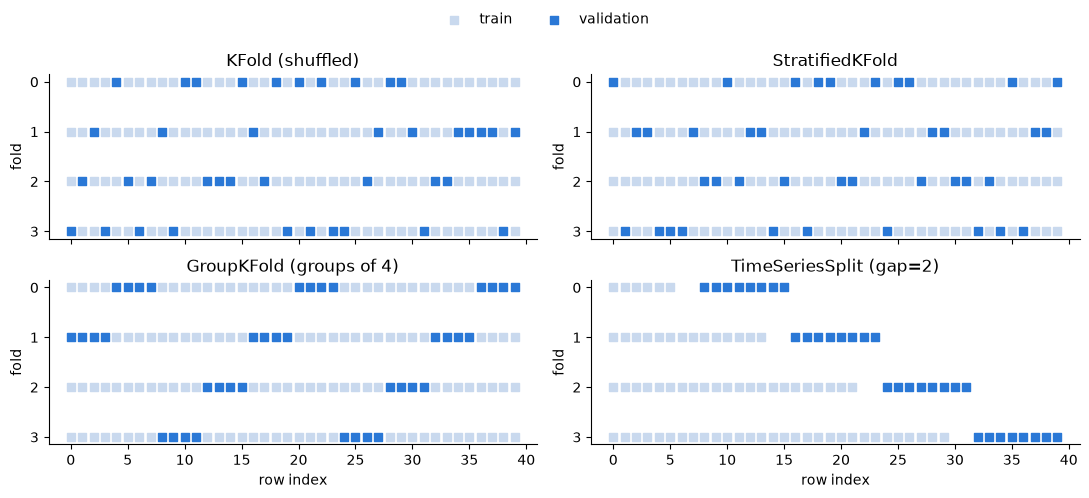

In [5]:
from sklearn.model_selection import StratifiedKFold, GroupKFold, TimeSeriesSplit

n = 40
toy_y = np.r_[np.zeros(30), np.ones(10)].astype(int)
toy_groups = np.repeat(np.arange(10), 4)
splitters = {
    "KFold (shuffled)": KFold(4, shuffle=True, random_state=0),
    "StratifiedKFold": StratifiedKFold(4, shuffle=True, random_state=0),
    "GroupKFold (groups of 4)": GroupKFold(4),
    "TimeSeriesSplit (gap=2)": TimeSeriesSplit(4, gap=2),
}
fig, axes = plt.subplots(2, 2, figsize=(11, 5), sharex=True)
for ax, (name, splitter) in zip(axes.ravel(), splitters.items()):
    for i, (tr, va) in enumerate(splitter.split(np.zeros(n), toy_y, toy_groups)):
        ax.scatter(tr, [i] * len(tr), marker="s", s=30, color="#c9d9ee", label="train" if i == 0 else None)
        ax.scatter(va, [i] * len(va), marker="s", s=30, color=PALETTE[0], label="validation" if i == 0 else None)
    ax.set_title(name); ax.set_yticks(range(4)); ax.set_ylabel("fold"); ax.invert_yaxis(); ax.grid(False)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=2)
for ax in axes[1]: ax.set_xlabel("row index")
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

## 5. Leakage

Leakage = information in training that won't be available at prediction time. It makes CV scores look great and production scores bad.
Common forms:
- **Preprocessing on all the data** (scaling, imputing, *feature selection*, target encoding) before splitting.
- **Group leakage**: near-duplicate rows (same person/family/store) in both train and validation.
- **Time leakage**: features computed with future data, or shuffled CV on time series.
- **Target leakage**: a feature that's a consequence of the target (e.g. "refund issued" when predicting "complaint").

### Demo A — feature selection outside the CV loop
Pure noise: 200 rows, 5,000 random features, random labels. No model can beat 50%.

In [6]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

Xn = rng.normal(size=(200, 5000))
yn = rng.integers(0, 2, size=200)

# WRONG: pick the 20 "best" features using all labels, then cross-validate.
X_sel = SelectKBest(f_classif, k=20).fit_transform(Xn, yn)
leaky = cross_val_score(LogisticRegression(max_iter=1000), X_sel, yn, cv=5).mean()

# RIGHT: selection lives inside the pipeline, so it's re-fit on each training fold only.
pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
honest = cross_val_score(pipe, Xn, yn, cv=5).mean()

print(f"leaky CV accuracy : {leaky:.2f}   <- looks like a real signal")
print(f"honest CV accuracy: {honest:.2f}   <- the truth: coin flip")

leaky CV accuracy : 0.84   <- looks like a real signal
honest CV accuracy: 0.55   <- the truth: coin flip


**Lesson:** anything that *learns from data* (scalers, imputers, encoders, selectors) goes in a `Pipeline`, so `cross_val_score` re-fits it per fold.

### Demo B — group leakage
Rows come in groups of 5 (think: families on a ship, or repeat visits by a patient). Each group shares an unobserved effect on the target, and some features identify the group (e.g. cabin number, surname) without *explaining* that effect.
A flexible model can memorise "this group → this value". Plain KFold rewards that; GroupKFold doesn't.

In [7]:
from sklearn.ensemble import RandomForestRegressor

n_groups, per_group = 300, 5
g = np.repeat(np.arange(n_groups), per_group)
group_effect = rng.normal(size=n_groups)                      # hidden, group-level
group_id_feats = rng.normal(size=(n_groups, 3))[g]            # identifies the group, no real relationship
row_feats = rng.normal(size=(len(g), 2))                      # genuinely useful row-level features
Xg = np.hstack([group_id_feats, row_feats])
yg = group_effect[g] + 0.8 * row_feats[:, 0] + 0.5 * rng.normal(size=len(g))

rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=SEED)
r2_kfold = cross_val_score(rf, Xg, yg, cv=KFold(5, shuffle=True, random_state=SEED), scoring="r2").mean()
r2_group = cross_val_score(rf, Xg, yg, cv=GroupKFold(5), groups=g, scoring="r2").mean()
print(f"KFold R²     : {r2_kfold:.2f}   <- includes memorised group effects")
print(f"GroupKFold R²: {r2_group:.2f}   <- what you'd get on new groups")

KFold R²     : 0.40   <- includes memorised group effects
GroupKFold R²: 0.26   <- what you'd get on new groups


## 6. Which metric?

Pick the metric the problem is judged on, then choose a **loss that matches it** (most libraries let you set the objective).

| Task | Metric | Notes |
|---|---|---|
| Regression | **RMSE / MSE** | punishes big errors; optimal prediction is the conditional *mean* |
| | **MAE** | robust to outliers; optimal prediction is the conditional *median* |
| | **R²** | 1 − MSE/Var(y); 0 = as good as predicting the mean. On noisy targets (returns) good models have R² of ~0.01 |
| | MAPE / RMSLE | relative errors; positive targets spanning orders of magnitude |
| Classification | **Log loss** | judges probabilities; use when probabilities matter |
| | **ROC AUC** | ranking quality, threshold-free, insensitive to class balance |
| | **PR AUC / F1** | rare positive class |
| | Accuracy | only when classes are balanced and errors cost the same |

## Checklist
- [ ] Baseline score written down
- [ ] Splitter matches deployment (groups? time?)
- [ ] All preprocessing inside a `Pipeline` or computed inside the fold
- [ ] Report CV mean **and** spread
- [ ] Test set used once